# PARDON-SOH: Provenance-Aware Reliability-Gated Degradation Observer

**Research prototype — not a published or validated architecture.** This notebook tests whether explicitly distinguishing *observed charging evidence* from *unknown operating history* improves **1-, 3-, and 5-cycle-ahead SOH forecasts**. The model uses the five selected CALCE CX2 charging indicators; it does **not** assume a missing recording interval is rest.

**Experimental controls**: OLS (CC+CV), masked Direct Transformer, masked Time-Aware Transformer, matched provenance-input Transformer, fixed-update Observer, and learned reliability-gated PARDON-SOH.

**Design:** data-derived availability indicators, history-provenance metadata, constrained slow latent trend plus unconstrained measured-capacity residual, uncertainty output, synthetic missing-input training and stress tests, battery-disjoint evaluation, saved model weights/metrics. No target SOH or future-cycle features enter inputs.

**Important limitations:** All five selected indicators come from completed charging data, not truly partial charges. Feature-masking scenarios simulate missing indicators, not real partial-charge curves. A strictly decreasing latent state is a structural prior; its interpretation as physically irreversible capacity loss is **not identifiable** without separate experiments. The seven-cell dataset and previously inspected CX2_38 prevent a genuinely unseen external test claim.

## 0 · Running instructions
1. Install `torch`, `numpy`, `pandas`, `scikit-learn`, `matplotlib`, `joblib` if needed.
2. Set `RUN_MODE = 'smoke'` to verify functionality (fast, non-research results).
3. Change to `RUN_MODE = 'full_fixed'` for original 5-cell training / CX2_36 validation / CX2_38 evaluation, or **`RUN_MODE = 'full_lobo'`** for 7 outer held-out cells with 1 inner validation cell each.
4. Keep model selection on validation data; do not rank designs by test-set performance. Larger nested hyperparameter searches can be added after a promising proof of concept.

Training-only 3-percentage-point filtering is **experimental**; we keep untouched validation and held-out evaluation labels. In LOBO mode, filters are re-created from each fold's training cells only, and gaps caused by filtering never masquerade as natural unobserved history.

In [1]:
# Optional: run only if dependencies are missing.
# %pip install torch numpy pandas scikit-learn matplotlib joblib

In [2]:
import os, json, random, time, hashlib, math, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import joblib
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from IPython.display import display

RUN_MODE = 'smoke'  # 'smoke', 'full_fixed', 'full_lobo'
PREFERRED_DIR = Path(r'C:\Projects\Battery_Soh\pre processed ready to use data')
DATA_DIR = PREFERRED_DIR if PREFERRED_DIR.is_dir() else Path('/mnt/data/pre processed ready to use data')
if not DATA_DIR.is_dir():
    raise FileNotFoundError('Set DATA_DIR to the folder containing train.csv, validation.csv, test.csv')
OUT = DATA_DIR / 'pardon_soh_results' / RUN_MODE
OUT.mkdir(parents=True, exist_ok=True)
(OUT/'checkpoints').mkdir(exist_ok=True)
(OUT/'predictions').mkdir(exist_ok=True)

FEATURES = ['cc_duration_s','cv_duration_s','dva_peak','ic_peak_voltage','ic_peak_width']
HORIZONS = (1, 3, 5)
LOOKBACK = 12
FILTER_TRAIN_JUMPS = True
SOH_JUMP = 0.03
MAX_INTERNAL_GAP_DAYS = 30.0  # long unobserved stretches beyond this cause sequence reset
MAX_INTERNAL_CYCLE_GAP = 50
HIDDEN = 48
BATCH_SIZE = 128
LR = 1e-3
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0   # Windows/Jupyter safe
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SCENARIOS = ('clean', 'no_cc', 'no_cv', 'random30', 'history_block')
EVAL_MASK_SEED = 31415  # identical stress-test masks for every architecture and run
MODEL_NAMES = ('ols_cc_cv','direct_masked','time_masked','provenance_masked','observer_fixed','pardon_gated')
SELECTION_CLEAN_WEIGHT = 0.60  # preregistered: clean + CC missing validation RMSE

if RUN_MODE == 'smoke':
    EPOCHS, PATIENCE, SEEDS = 1, 1, (42,)
    FOLD_LIMIT = 1
    MAX_TRAIN_BATCHES, MAX_EVAL_BATCHES = 2, 2
elif RUN_MODE == 'full_fixed':
    EPOCHS, PATIENCE, SEEDS = 70, 12, (42,123,2026)
    FOLD_LIMIT = 1
    MAX_TRAIN_BATCHES = MAX_EVAL_BATCHES = None
elif RUN_MODE == 'full_lobo':
    EPOCHS, PATIENCE, SEEDS = 70, 12, (42,123,2026)
    FOLD_LIMIT = None
    MAX_TRAIN_BATCHES = MAX_EVAL_BATCHES = None
else:
    raise ValueError('Unknown RUN_MODE')

print('Mode:',RUN_MODE,'device:',DEVICE,'output:',OUT)

Mode: smoke device: cuda output: C:\Projects\Battery_Soh\pre processed ready to use data\pardon_soh_results\smoke


## 1 · Data quality and fold setup

The fixed benchmark uses your `train_final_filtered.csv` if present. Seven-cell LOBO recomputes jump flags **from training batteries only**. Source file transitions, ordinal jumps and elapsed time are descriptive provenance signals, **not proof** of rest, reliability or electrochemical recovery. No quality flag is derived from future SOH.

In [3]:
REQUIRED = ['battery','cycle_ordinal','cycle_start','soh']+FEATURES

def read_frame(path):
    df = pd.read_csv(path)
    missing = sorted(set(REQUIRED)-set(df.columns))
    if missing: raise ValueError(f'{path.name}: missing columns {missing}')
    df['cycle_start'] = pd.to_datetime(df['cycle_start'], errors='raise')
    df['battery'] = df['battery'].astype(str)
    df['cycle_ordinal'] = pd.to_numeric(df['cycle_ordinal'],errors='raise').astype(int)
    for col in FEATURES+['soh']:
        df[col] = pd.to_numeric(df[col],errors='coerce')
    df = df.dropna(subset=FEATURES+['soh','cycle_start']).copy()
    if 'row_id' not in df.columns: df['row_id'] = np.arange(len(df))
    if 'source_identifiers' not in df.columns: df['source_identifiers'] = ''
    return df.sort_values(['battery','cycle_ordinal','cycle_start']).reset_index(drop=True)

raw_train = read_frame(DATA_DIR/'train.csv')
raw_val = read_frame(DATA_DIR/'validation.csv')
raw_test = read_frame(DATA_DIR/'test.csv')
all_raw = pd.concat([raw_train,raw_val,raw_test],ignore_index=True)
if all_raw.duplicated(['battery','cycle_ordinal']).any():
    raise ValueError('Duplicate battery/cycle ordinal; audit the source before training.')
print('Source rows:',all_raw.groupby('battery').size().to_dict())

filtered_file = DATA_DIR/'train_final_filtered.csv'
fixed_train = read_frame(filtered_file) if filtered_file.exists() else None
if fixed_train is None:
    # Preserve user's intended training exclusion rule if filtered export is missing.
    fixed_train,_ = training_filter(raw_train) if 'training_filter' in globals() else (None,None)
    if fixed_train is None:
        g=raw_train.sort_values(['battery','cycle_ordinal']).copy()
        grp=g.groupby('battery',sort=False)
        jump=grp['cycle_ordinal'].diff().eq(1) & grp['soh'].diff().abs().gt(SOH_JUMP)
        before=jump.groupby(g['battery']).shift(-1,fill_value=False)
        fixed_train=g.loc[~(jump|before)].copy()
    print('Filtered file absent; recreated experimental 3pp training filter in memory (original data unchanged).')
if not set(fixed_train['row_id']).issubset(set(raw_train['row_id'])):
    raise ValueError('Filtered training file contains rows absent from original train.csv')

# Exclusions are used to detect training-induced gaps, never to inform predictions.
def training_filter(df):
    if not FILTER_TRAIN_JUMPS:
        return df.copy(), set()
    g = df.sort_values(['battery','cycle_ordinal']).copy()
    gr = g.groupby('battery',sort=False)
    jumps = (gr['cycle_ordinal'].diff().eq(1) & gr['soh'].diff().abs().gt(SOH_JUMP))
    before = jumps.groupby(g['battery']).shift(-1,fill_value=False)
    bad = jumps | before
    return g.loc[~bad].copy(), set(g.loc[bad,'row_id'].astype(str))

cells = sorted(all_raw['battery'].unique().tolist())
if RUN_MODE == 'full_lobo':
    folds = []
    for i,held in enumerate(cells):
        val_cell = cells[(i+1)%len(cells)]
        train_cells = [c for c in cells if c not in (held,val_cell)]
        folds.append(dict(name=f'held_{held}',test=all_raw[all_raw.battery==held].copy(),
                          val=all_raw[all_raw.battery==val_cell].copy(),
                          train_raw=all_raw[all_raw.battery.isin(train_cells)].copy(),
                          original_train=None,train_cells=train_cells,val_cell=val_cell,held=held))
else:
    folds = [dict(name='fixed_CX2_38',train_raw=raw_train.copy(),original_train=fixed_train.copy(),
                  val=raw_val.copy(),test=raw_test.copy(),train_cells=sorted(raw_train.battery.unique()),
                  val_cell='CX2_36',held='CX2_38')]
if FOLD_LIMIT is not None: folds = folds[:FOLD_LIMIT]
print('Outer folds:', [(f['held'],f['val_cell']) for f in folds])

Source rows: {'CX2_16': 1899, 'CX2_33': 1488, 'CX2_34': 1554, 'CX2_35': 1630, 'CX2_36': 1743, 'CX2_37': 1219, 'CX2_38': 1477}
Outer folds: [('CX2_38', 'CX2_36')]


In [4]:
def prepare_fold(f):
    original = f['train_raw'].copy()
    if f['original_train'] is not None:
        tr = f['original_train'].copy()
        removed = set(original['row_id'].astype(str))-set(tr['row_id'].astype(str))
    else:
        tr,removed = training_filter(original)
    tr = tr.sort_values(['battery','cycle_ordinal']).reset_index(drop=True)
    scaler = StandardScaler().fit(tr[FEATURES].to_numpy(dtype=float))
    dt_valid = []
    for _,g in tr.groupby('battery'):
        dcy = g.cycle_ordinal.diff()
        dh = g.cycle_start.diff().dt.total_seconds()/3600
        dt_valid.extend(dh[(dcy==1)&(dh>0)&(dh<=24)].dropna().tolist())
    median_hours = float(np.median(dt_valid)) if dt_valid else 4.0
    return tr, removed, scaler, max(median_hours,0.1)

for f in folds:
    tr, removed, scaler, mh = prepare_fold(f)
    print(f['name'], 'train rows:',len(tr),'removed:',len(removed),
          'val rows:',len(f['val']),'test rows:',len(f['test']), 'median step hours:',round(mh,2))

fixed_CX2_38 train rows: 7690 removed: 100 val rows: 1743 test rows: 1477 median step hours: 3.88


## 2 · Leakage-safe sample construction

Each example uses observations ending at cycle `k` to predict the measured SOH at **exact** ordinal `k+h` (h = 1, 3, 5); the target's features are never supplied. The same forecast-origin/target pairs are used by all models. Within histories, missing ordinals and irregular recording intervals are encoded as *unknown observation history*, not verified rest. Windows do not bridge cycles removed by our experimental training filter.

In [5]:
# Observed histories: [X normalized five], [dt/log step, log cycle gap, source transition]
# Unknown history is flagged by missing ordinals or long intervals, but NOT called resting.

def make_windows(frame, scaler, median_hours, removed_ids=None):
    removed_ids = set(removed_ids or [])
    examples=[]
    for battery,g0 in frame.groupby('battery',sort=True):
        g=g0.sort_values(['cycle_ordinal','cycle_start']).reset_index(drop=True)
        # Original recording intervals, restricted only by explicit hard safety cutoffs.
        parts=[]; start=0
        for i in range(1,len(g)):
            gap_c=int(g.loc[i,'cycle_ordinal']-g.loc[i-1,'cycle_ordinal'])
            gap_h=(g.loc[i,'cycle_start']-g.loc[i-1,'cycle_start']).total_seconds()/3600
            # Don't turn filtered-out records into 'naturally unknown' history.
            crosses_filtered=False
            if removed_ids and gap_c>1:
                # Use original per-row ordinal identifiers when present, not target label.
                crosses_filtered=any(f'{battery}:{ord_:05d}' in removed_ids for ord_ in range(int(g.loc[i-1,'cycle_ordinal'])+1,int(g.loc[i,'cycle_ordinal'])))
            if (gap_c<=0 or gap_c>MAX_INTERNAL_CYCLE_GAP or gap_h<=0 or
                gap_h>24*MAX_INTERNAL_GAP_DAYS or crosses_filtered):
                if i-start>=LOOKBACK: parts.append(g.iloc[start:i].copy())
                start=i
        if len(g)-start>=LOOKBACK: parts.append(g.iloc[start:].copy())

        for part in parts:
            part=part.reset_index(drop=True)
            n=len(part)
            values=scaler.transform(part[FEATURES].to_numpy(dtype=float)).astype('float32')
            cycles=part.cycle_ordinal.to_numpy(dtype=np.int64)
            t=part.cycle_start
            delta_h=np.ones(n,dtype='float32')*median_hours
            delta_c=np.ones(n,dtype='float32')
            if n>1:
                delta_h[1:] = (t.diff().dt.total_seconds()/3600).to_numpy()[1:].astype('float32')
                delta_c[1:] = np.diff(cycles).astype('float32')
            prev_src=part.source_identifiers.astype(str).shift(1)
            src_change=(part.source_identifiers.astype(str)!=prev_src).astype('float32').to_numpy(copy=True)
            src_change[0]=0.
            prov=np.column_stack((np.log1p(delta_h/median_hours),
                                  np.log1p(np.maximum(delta_c-1,0)),src_change)).astype('float32')
            # Only targets inside the same safety-bounded source segment are eligible.
            pos = {int(k):i for i,k in enumerate(cycles)}
            for end in range(LOOKBACK-1,n):
                k=int(cycles[end])
                x=values[end-LOOKBACK+1:end+1]
                p=prov[end-LOOKBACK+1:end+1]
                for horizon in HORIZONS:
                    target_i=pos.get(k+horizon)
                    if target_i is None or target_i<=end: continue
                    examples.append((x.copy(),p.copy(),float(horizon),
                                     float(part.loc[target_i,'soh']),battery,k,int(k+horizon),
                                     str(part.loc[target_i,'row_id'])))
    if not examples:
        raise RuntimeError('No eligible windows. Check LOOKBACK and segment restrictions.')
    X=np.stack([r[0] for r in examples]); P=np.stack([r[1] for r in examples]);
    h=np.array([r[2] for r in examples],dtype=np.float32)
    y=np.array([r[3] for r in examples],dtype=np.float32)
    meta=pd.DataFrame(dict(battery=[r[4] for r in examples],origin_cycle=[r[5] for r in examples],
                           target_cycle=[r[6] for r in examples],target_row_id=[r[7] for r in examples],horizon=h.astype(int)))
    assert X.shape[1:]==(LOOKBACK,5) and P.shape[1:]==(LOOKBACK,3)
    return {'x':X,'p':P,'h':h,'y':y,'meta':meta}

# A filter exclusion is identified by the original cycle_id, when available.
def excluded_cycle_ids(original,filtered):
    if 'cycle_id' not in original or 'cycle_id' not in filtered: return set()
    return set(original['cycle_id'].astype(str))-set(filtered['cycle_id'].astype(str))

f=folds[0]
tr,_,scaler,mh=prepare_fold(f)
remove_cycle_ids=excluded_cycle_ids(f['train_raw'],tr)
train_pack=make_windows(tr,scaler,mh,remove_cycle_ids)
val_pack=make_windows(f['val'],scaler,mh)
test_pack=make_windows(f['test'],scaler,mh)
print('Forecast windows (train,val,test):',len(train_pack['y']),len(val_pack['y']),len(test_pack['y']))
print('Train known/unknown-gap history proportion:',round(float((train_pack['p'][:,:,1]>0).mean()),4))
print('First example:',train_pack['meta'].iloc[0].to_dict())

Forecast windows (train,val,test): 20624 4860 4089
Train known/unknown-gap history proportion: 0.0567
First example: {'battery': 'CX2_16', 'origin_cycle': 13, 'target_cycle': 14, 'target_row_id': '12', 'horizon': 1}


## 3 · Availability masks and controlled stress tests

At training time, masks are sampled without looking at labels. Models receive both standardized feature values (zero-filled **after** scaling) and their availability masks. At evaluation time, each scenario is deterministic per fold and example. `history_block` removes a contiguous block of observations; `no_cc` and `no_cv` remove those entire feature channels. This is **simulated** feature missingness, not observed partial-charge data.

In [6]:
class ForecastDataset(Dataset):
    def __init__(self, pack, scenario='train', seed=42):
        self.pack=pack; self.scenario=scenario; self.seed=seed
    def __len__(self): return len(self.pack['y'])
    def __getitem__(self,i):
        x=self.pack['x'][i].copy(); p=self.pack['p'][i].copy()
        m=np.ones_like(x,dtype=np.float32)
        if self.scenario=='train':
            # Stochastic feature-channel and element loss, independent of SOH.
            if np.random.rand()<0.30:
                m[:,np.random.randint(0,5)]=0
            m[np.random.rand(*m.shape)<0.08]=0
            if np.random.rand()<0.15:
                start=np.random.randint(0,LOOKBACK-2)
                m[start:start+3,:]=0
        elif self.scenario!='clean':
            # Stable per-example deterministic masks across architectures and runs.
            key=f"{self.seed}|{self.pack['meta'].iloc[i]['battery']}|{self.pack['meta'].iloc[i]['origin_cycle']}|{self.pack['h'][i]}|{self.scenario}"
            seed=int(hashlib.sha256(key.encode()).hexdigest()[:8],16)
            rng=np.random.default_rng(seed)
            if self.scenario=='no_cc': m[:,0]=0
            elif self.scenario=='no_cv': m[:,1]=0
            elif self.scenario=='random30': m[rng.random(m.shape)<0.30]=0
            elif self.scenario=='history_block':
                start=int(rng.integers(0,LOOKBACK-3)); m[start:start+4,:]=0
            else: raise ValueError(self.scenario)
        # Never invent a battery measurement for an absent feature.
        x *= m
        return (torch.from_numpy(x),torch.from_numpy(m),torch.from_numpy(p),
                torch.tensor(self.pack['h'][i]/5.0,dtype=torch.float32),
                torch.tensor(self.pack['y'][i],dtype=torch.float32))

def make_loader(pack,scenario='clean',seed=42,shuffle=False):
    return DataLoader(ForecastDataset(pack,scenario,seed),batch_size=BATCH_SIZE,
                      shuffle=shuffle,num_workers=NUM_WORKERS,pin_memory=(DEVICE.type=='cuda'))

one=next(iter(make_loader(train_pack,'clean')))
print('Shapes x,mask,provenance,horizon,label:',*[tuple(z.shape) for z in one])
assert torch.all(one[1]==1), 'Clean scenario must not hide measurements'
assert (train_pack['meta'].target_cycle > train_pack['meta'].origin_cycle).all()

Shapes x,mask,provenance,horizon,label: (128, 12, 5) (128, 12, 5) (128, 12, 3) (128,) (128,)


## 4 · Model architectures and physics prior

- **OLS**: current last-observed CC/CV + masks + horizon, with training-time feature masking.
- **Direct Transformer**: five observations + availability mask; no elapsed-time input.
- **Time-aware Transformer**: same plus elapsed-time channel.
- **Provenance Transformer**: same plus elapsed time, unobserved-cycle gap, source-boundary flag.
- **Fixed-update Observer**: matched nonlinear state update with gate fixed at 1 where evidence exists.
- **PARDON learned gate**: explicit learned reliability gate controlling corrections to a propagated state; gate forced to zero when no feature is observed.

Both observers have an intrinsically non-increasing *latent slow trend* and a separate unconstrained residual output. The slow trend is **not proven** to equal physical irreversible capacity. No label-based quality score is provided to the encoder.

In [7]:
class TransformerForecast(nn.Module):
    def __init__(self, kind='direct_masked', hidden=HIDDEN):
        super().__init__()
        self.kind=kind
        n_extra={'direct_masked':0,'time_masked':1,'provenance_masked':3}[kind]
        self.embedding=nn.Linear(10+n_extra,hidden)
        self.position=nn.Parameter(torch.zeros(1,LOOKBACK,hidden))
        layer=nn.TransformerEncoderLayer(d_model=hidden,nhead=4,dim_feedforward=hidden*2,
                                         dropout=0.10,activation='gelu',batch_first=True,norm_first=True)
        self.encoder=nn.TransformerEncoder(layer,num_layers=2,enable_nested_tensor=False)
        self.head=nn.Sequential(nn.Linear(hidden+1,hidden),nn.GELU(),nn.Linear(hidden,2))
        nn.init.normal_(self.position,std=0.01)
    def forward(self,x,m,p,h):
        inp=[x,m]
        if self.kind=='time_masked': inp.append(p[:,:,:1])
        elif self.kind=='provenance_masked': inp.append(p)
        z=self.embedding(torch.cat(inp,dim=-1))+self.position
        z=self.encoder(z)[:,-1,:]
        out=self.head(torch.cat([z,h[:,None]],dim=1))
        return out[:,0],out[:,1].clamp(-11,-3),{}

class EvidenceObserver(nn.Module):
    def __init__(self,gated=True,hidden=HIDDEN):
        super().__init__()
        self.gated=gated
        self.obs=nn.Sequential(nn.Linear(13,hidden),nn.GELU(),nn.Linear(hidden,hidden),nn.Tanh())
        self.z0=nn.Parameter(torch.zeros(hidden))
        self.decay=nn.Parameter(torch.full((hidden,),-3.0))
        self.candidate=nn.Sequential(nn.Linear(hidden*2,hidden),nn.GELU(),nn.Linear(hidden,hidden),nn.Tanh())
        self.gate=nn.Sequential(nn.Linear(hidden*2+2,hidden//2),nn.GELU(),nn.Linear(hidden//2,1))
        # Slow trend may decrease. Observation residual may increase or decrease.
        self.initial_slow=nn.Parameter(torch.tensor(0.99))
        self.rate=nn.Sequential(nn.Linear(hidden,hidden//2),nn.GELU(),nn.Linear(hidden//2,1))
        nn.init.constant_(self.rate[-1].bias,-5.0)
        self.head=nn.Sequential(nn.Linear(hidden+1,hidden),nn.GELU(),nn.Linear(hidden,2))
        self.future_rate=nn.Sequential(nn.Linear(hidden,1))
        nn.init.constant_(self.future_rate[-1].bias,-5.0)
    def forward(self,x,m,p,h):
        batch=x.size(0)
        z=self.z0[None,:].expand(batch,-1)
        slow=self.initial_slow.expand(batch)
        gates=[]; latent=[]
        for t in range(x.size(1)):
            pt=p[:,t,:]
            # 0th provenance channel is log(1 + dt/median_dt)
            decay=torch.exp(-torch.nn.functional.softplus(self.decay)[None,:]*pt[:,:1])
            prior=decay*z
            emb=self.obs(torch.cat([x[:,t,:],m[:,t,:],pt],dim=-1))
            candidate=self.candidate(torch.cat([prior,emb],dim=-1))
            observed=(m[:,t,:].sum(dim=1,keepdim=True)>0).to(x.dtype)
            if self.gated:
                # Inputs available at prediction time: observed fraction and gap flag.
                quality=torch.cat([m[:,t,:].mean(dim=1,keepdim=True),
                                   (pt[:,1:2]>0).to(x.dtype)],dim=1)
                g=torch.sigmoid(self.gate(torch.cat([prior,emb,quality],dim=1)))*observed
            else:
                g=observed
            z=prior+g*(candidate-prior)
            # Physically inspired slow-trend prior; NOT supervised as actual irreversible capacity.
            step_scale=torch.expm1(pt[:,1]).add(1).clamp(1,MAX_INTERNAL_CYCLE_GAP)
            slow=slow-0.01*torch.nn.functional.softplus(self.rate(z)).squeeze(-1)*step_scale
            gates.append(g.squeeze(-1));latent.append(slow)
        future_slow=slow-0.01*torch.nn.functional.softplus(self.future_rate(z)).squeeze(-1)*(h*5)
        residual=self.head(torch.cat([z,h[:,None]],dim=1))
        mean=future_slow+residual[:,0]
        log_var=residual[:,1].clamp(-11,-3)
        diag={'gate_mean':torch.stack(gates,dim=1).mean(dim=1),
              'slow_state':slow,'future_slow':future_slow}
        return mean,log_var,diag

def make_model(name):
    if name in ('direct_masked','time_masked','provenance_masked'):
        return TransformerForecast(name)
    if name in ('observer_fixed','pardon_gated'):
        return EvidenceObserver(gated=(name=='pardon_gated'))
    raise KeyError(name)

# Structural tests: no future features; zero observed features must cause zero correction.
xb,mb,pb,hb,yb=one
for name in MODEL_NAMES[1:]:
    model=make_model(name)
    with torch.no_grad():
        pred,lv,diag=model(xb[:4],mb[:4],pb[:4],hb[:4])
    assert pred.shape==(4,) and torch.isfinite(pred).all() and torch.isfinite(lv).all(),name

mzero=torch.zeros_like(mb[:4])
model=make_model('pardon_gated')
with torch.no_grad():
    _,_,d=model(xb[:4]*0,mzero,pb[:4],hb[:4])
assert torch.all(d['gate_mean']==0), 'No evidence must imply no observation correction'
print('Neural architecture and no-evidence gating checks passed')

Neural architecture and no-evidence gating checks passed


## 5 · Training, model selection and uncertainty

Model weights are optimized with AdamW; no GWO is applied here because we first need to isolate the evidence-gate contribution. Early stopping uses a pre-specified validation metric: `0.6 × clean RMSE + 0.4 × no-CC RMSE`. Evaluation stress masks are deterministic. All models are evaluated on identical origin-target pairs. The learned Gaussian variance is **not** automatically calibrated; validation-based empirical scaling is reported separately and does not provide a distribution-free guarantee under cross-battery shift.

In [8]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def batch_to_device(b): return [a.to(DEVICE,non_blocking=True) for a in b]

def nn_loss(mean,logvar,target):
    mse=torch.mean((mean-target)**2)
    # Small Gaussian likelihood term to learn meaningful relative uncertainty.
    nll=0.5*torch.mean(logvar+(target-mean).square()*torch.exp(-logvar))
    return mse+0.001*nll

@torch.no_grad()
def predict_net(model,pack,scenario='clean',seed=42,limited=False):
    model.eval(); preds=[]; logs=[]; gates=[]; slow=[]
    loader=make_loader(pack,scenario,seed)
    count=0
    for b in loader:
        x,m,p,h,y=batch_to_device(b)
        mu,lv,d=model(x,m,p,h)
        preds.append(mu.cpu().numpy());logs.append(lv.cpu().numpy())
        if 'gate_mean' in d: gates.append(d['gate_mean'].cpu().numpy())
        if 'future_slow' in d: slow.append(d['future_slow'].cpu().numpy())
        count+=len(x)
        if limited and MAX_EVAL_BATCHES is not None and len(preds)>=MAX_EVAL_BATCHES: break
    mu=np.concatenate(preds);lv=np.concatenate(logs)
    return dict(y=pack['y'][:len(mu)],pred=mu,log_var=lv,
                gate=np.concatenate(gates) if gates else np.full(len(mu),np.nan),
                slow=np.concatenate(slow) if slow else np.full(len(mu),np.nan),
                meta=pack['meta'].iloc[:len(mu)].reset_index(drop=True))

def score(arr): return float(np.sqrt(np.mean((arr['pred']-arr['y'])**2)))

def train_nn(name,pack_train,pack_val,seed,fold_id):
    set_seed(seed)
    model=make_model(name).to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    train_loader=make_loader(pack_train,'train',seed,shuffle=True)
    best=float('inf');best_epoch=0;best_state=None;stale=0;hist=[]
    t0=time.perf_counter()
    for epoch in range(1,EPOCHS+1):
        model.train(); losses=[]
        for j,b in enumerate(train_loader):
            x,m,p,h,y=batch_to_device(b)
            optimizer.zero_grad(set_to_none=True)
            mu,lv,_=model(x,m,p,h)
            loss=nn_loss(mu,lv,y)
            if not torch.isfinite(loss):raise FloatingPointError(f'Nonfinite loss: {name}')
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            optimizer.step();losses.append(float(loss.item()))
            if MAX_TRAIN_BATCHES is not None and j+1>=MAX_TRAIN_BATCHES:break
        clean=score(predict_net(model,pack_val,'clean',EVAL_MASK_SEED,limited=(RUN_MODE=='smoke')))
        absent=score(predict_net(model,pack_val,'no_cc',EVAL_MASK_SEED,limited=(RUN_MODE=='smoke')))
        objective=SELECTION_CLEAN_WEIGHT*clean+(1-SELECTION_CLEAN_WEIGHT)*absent
        hist.append(dict(fold=fold_id,model=name,seed=seed,epoch=epoch,train_loss=np.mean(losses),
                         validation_clean_rmse=clean,validation_no_cc_rmse=absent,selection_score=objective))
        if objective<best-1e-7:
            best=objective;best_epoch=epoch;stale=0
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:
            stale+=1
            if stale>=PATIENCE:break
    model.load_state_dict(best_state)
    return model,best,best_epoch,pd.DataFrame(hist),time.perf_counter()-t0

# OLS: same masked histories, but only latest CC/CV + their availability + horizon.
def ols_matrix(pack,scenario,seed):
    xs=[];ys=[]
    ds=ForecastDataset(pack,scenario,seed)
    for i in range(len(ds)):
        x,m,p,h,y=ds[i]
        xs.append([float(x[-1,0]),float(x[-1,1]),float(m[-1,0]),float(m[-1,1]),float(h)])
        ys.append(float(y))
    return np.asarray(xs,dtype=float),np.asarray(ys,dtype=float)

def fit_ols(pack,seed):
    # Random training masking, same purpose and information constraints as neural controls.
    set_seed(seed)
    Xparts=[];Yparts=[]
    for _ in range(3 if RUN_MODE!='smoke' else 1):
        x,y=ols_matrix(pack,'train',seed)
        Xparts.append(x);Yparts.append(y)
    return LinearRegression().fit(np.vstack(Xparts),np.concatenate(Yparts))

def predict_ols(model,pack,scenario,seed,limited=False):
    x,y=ols_matrix(pack,scenario,seed)
    if limited and MAX_EVAL_BATCHES is not None:
        x=x[:BATCH_SIZE*MAX_EVAL_BATCHES];y=y[:len(x)]
    p=model.predict(x)
    return dict(y=y,pred=p,log_var=np.zeros(len(p)),gate=np.full(len(p),np.nan),
                slow=np.full(len(p),np.nan),meta=pack['meta'].iloc[:len(p)].reset_index(drop=True))

## 6 · Metrics, intervals, and provenance diagnostics

Use the same forecast rows across all models. For each stress scenario, calibrate a simple 90% predictive interval on the inner validation cell using an empirical quantile of the normalized absolute residual. This is descriptive coverage calibration, **not** a formal exchangeability guarantee for new battery cells.

In [9]:
from collections import defaultdict

def get_predictions(name,model,pack,scenario,seed,limited=False):
    return (predict_ols(model,pack,scenario,seed,limited) if name=='ols_cc_cv'
            else predict_net(model,pack,scenario,seed,limited))

def sigma_from(result,name):
    return (np.ones_like(result['pred'],dtype=float) if name=='ols_cc_cv'
            else np.sqrt(np.exp(result['log_var'].astype(float))))

def calc_metrics(r,half_width):
    yt=np.asarray(r['y'],dtype=float);yp=np.asarray(r['pred'],dtype=float)
    err=yt-yp
    return {'n':len(yt),'rmse':float(np.sqrt(np.mean(err**2))),
            'mae':float(np.mean(np.abs(err))),
            'mape_pct':float(np.mean(np.abs(err)/np.maximum(np.abs(yt),1e-6))*100),
            'r2':float(r2_score(yt,yp)) if len(yt)>1 and np.var(yt)>0 else np.nan,
            'bias':float(np.mean(yp-yt)),
            'coverage90':float(np.mean(np.abs(err)<=half_width)),
            'interval_width90':float(2*np.mean(half_width))}

def val_quantile(val_result,name):
    r=np.abs(val_result['y']-val_result['pred']) / np.maximum(sigma_from(val_result,name),1e-7)
    return float(np.quantile(r,0.90))

def prediction_frame(r,name,fold,scenario,q):
    result=r['meta'].copy()
    result['model']=name;result['fold']=fold;result['scenario']=scenario
    result['y_true']=r['y'];result['y_pred']=r['pred']
    result['sigma']=sigma_from(r,name);result['interval_halfwidth']=q*result['sigma']
    result['gate_mean']=r['gate'];result['slow_state_proxy']=r['slow']
    return result

# Reproduce one model's forward pass from checkpoint saved with training-only preprocess.
def reload_saved_model(ckpt_path):
    payload=torch.load(ckpt_path,map_location='cpu',weights_only=False)
    model=make_model(payload['model_name'])
    model.load_state_dict(payload['weights']); model.eval()
    return model,payload['preprocess']

## 7 · Train, select and save models

Each fold trains all neural models with the same seeds and synthetic missingness policy. For each architecture, its best seed/epoch is chosen *only* from the **inner validation** cell, then each selected model is evaluated on the outer held-out cell across the same predefined stress scenarios.

`smoke` mode uses only a few minibatches/epochs and must **never** be reported as scientific performance. `full_fixed` is compatible with your previous 5/1/1 split; `full_lobo` is the primary generalization experiment. The latter uses seven cells that have been explored in previous work; external validation is still needed.

In [10]:
fold_records=[];all_metrics=[];all_histories=[];comparison=[];predictions_index=[]

for f in folds:
    print('\n====',f['name'],'held-out',f['held'],'validation',f['val_cell'],'====')
    tr,removed_ids,scaler,mh=prepare_fold(f)
    removed_cyc=excluded_cycle_ids(f['train_raw'],tr)
    tr_pack=make_windows(tr,scaler,mh,removed_cyc)
    va_pack=make_windows(f['val'],scaler,mh)
    te_pack=make_windows(f['test'],scaler,mh)
    print('windows:',len(tr_pack['y']),len(va_pack['y']),len(te_pack['y']))
    preprocess=dict(feature_names=FEATURES,scaler_mean=scaler.mean_.tolist(),
                    scaler_scale=scaler.scale_.tolist(),time_median_hours=mh,
                    lookback=LOOKBACK,horizons=list(HORIZONS),
                    max_internal_gap_days=MAX_INTERNAL_GAP_DAYS,
                    filter_train_jumps=FILTER_TRAIN_JUMPS,filtered_train_count=len(tr),
                    trained_batteries=f['train_cells'],validation_battery=f['val_cell'],heldout_battery=f['held'])
    file_base=OUT/'checkpoints'/f['name']
    file_base.mkdir(parents=True,exist_ok=True)
    joblib.dump(scaler,file_base/'train_scaler.joblib')
    (file_base/'preprocess.json').write_text(json.dumps(preprocess,indent=2))
    fold_records.append(dict(fold=f['name'],train_rows=len(tr),train_windows=len(tr_pack['y']),
                             val_windows=len(va_pack['y']),test_windows=len(te_pack['y']),
                             excluded_train_rows=len(removed_cyc),heldout=f['held']))
    for name in MODEL_NAMES:
        candidate_list=[]
        for seed in SEEDS:
            if name=='ols_cc_cv':
                model=fit_ols(tr_pack,seed)
                clean=score(get_predictions(name,model,va_pack,'clean',EVAL_MASK_SEED,RUN_MODE=='smoke'))
                masked=score(get_predictions(name,model,va_pack,'no_cc',EVAL_MASK_SEED,RUN_MODE=='smoke'))
                selection=SELECTION_CLEAN_WEIGHT*clean+(1-SELECTION_CLEAN_WEIGHT)*masked
                epoch=0;seconds=0;history=None
            else:
                model,selection,epoch,history,seconds=train_nn(name,tr_pack,va_pack,seed,f['name'])
                all_histories.append(history)
            candidate_list.append((selection,seed,epoch,seconds,model))
        candidate_list.sort(key=lambda z:z[0])
        selection,seed,epoch,seconds,model=candidate_list[0]
        print(f'{name:20s} best validation objective={selection:.5f} seed={seed}, epoch={epoch}')
        if name=='ols_cc_cv':
            checkpoint=file_base/(name+'_best.joblib')
            joblib.dump(dict(model=model,preprocess=preprocess,seed=seed),checkpoint)
            num_parameters=len(model.coef_)+1
        else:
            checkpoint=file_base/(name+'_best.pt')
            torch.save(dict(model_name=name,weights={k:v.cpu() for k,v in model.state_dict().items()},
                            preprocess=preprocess,seed=seed,best_epoch=epoch,
                            validation_selection_score=selection),checkpoint)
            num_parameters=sum(p.numel() for p in model.parameters())
        comparison.append(dict(fold=f['name'],model=name,seed=seed,best_epoch=epoch,
                               val_selection_score=selection,train_seconds=seconds,
                               parameters=num_parameters,checkpoint=str(checkpoint)))
        fold_prediction_frames=[]
        for scenario in SCENARIOS:
            # Calibration uses the validation battery, not held-out target labels.
            rv=get_predictions(name,model,va_pack,scenario,EVAL_MASK_SEED,RUN_MODE=='smoke')
            rt=get_predictions(name,model,te_pack,scenario,EVAL_MASK_SEED,RUN_MODE=='smoke')
            q=val_quantile(rv,name)
            width=q*sigma_from(rt,name)
            for h in HORIZONS:
                idx=(rt['meta'].horizon.to_numpy()==h)
                if not idx.any():continue
                sub={k:(v[idx] if isinstance(v,np.ndarray) and v.shape[:1]==rt['y'].shape[:1] else v) for k,v in rt.items() if k!='meta'}
                sub['meta']=rt['meta'].iloc[np.flatnonzero(idx)].reset_index(drop=True)
                metrics=calc_metrics(sub,width[idx])
                all_metrics.append(dict(fold=f['name'],heldout=f['held'],model=name,seed=seed,
                                        scenario=scenario,horizon=h,**metrics))
            fold_prediction_frames.append(prediction_frame(rt,name,f['name'],scenario,q))
        path=OUT/'predictions'/f'{f["name"]}_{name}.csv'
        pd.concat(fold_prediction_frames,ignore_index=True).to_csv(path,index=False)
        predictions_index.append(dict(fold=f['name'],model=name,predictions_file=str(path)))

metrics_df=pd.DataFrame(all_metrics)
metrics_df.to_csv(OUT/'outer_fold_metrics.csv',index=False)
pd.DataFrame(comparison).to_csv(OUT/'validation_selected_models.csv',index=False)
pd.DataFrame(fold_records).to_csv(OUT/'fold_audit.csv',index=False)
pd.DataFrame(predictions_index).to_csv(OUT/'prediction_file_index.csv',index=False)
if all_histories: pd.concat(all_histories,ignore_index=True).to_csv(OUT/'training_histories.csv',index=False)
print('\nFinished. Metrics:',OUT/'outer_fold_metrics.csv')


==== fixed_CX2_38 held-out CX2_38 validation CX2_36 ====
windows: 20624 4860 4089
ols_cc_cv            best validation objective=0.06725 seed=42, epoch=0
direct_masked        best validation objective=0.50444 seed=42, epoch=1
time_masked          best validation objective=0.37585 seed=42, epoch=1
provenance_masked    best validation objective=0.20858 seed=42, epoch=1
observer_fixed       best validation objective=0.08671 seed=42, epoch=1
pardon_gated         best validation objective=0.08807 seed=42, epoch=1

Finished. Metrics: C:\Projects\Battery_Soh\pre processed ready to use data\pardon_soh_results\smoke\outer_fold_metrics.csv


## 8 · Honest summary and pre-registered comparisons

Report **battery-macro** scores in LOBO mode, not only pooled-window scores. The primary comparison is learned-gate PARDON versus the fixed-update observer and provenance-matched Transformer, especially under `no_cc` and `history_block`. Clean-data deterioration counts against the method. Confidence intervals over seven cells are indicative only; battery count is small.

In [11]:
summary=(metrics_df.groupby(['model','scenario','horizon'],as_index=False)
         .agg(mean_cell_rmse=('rmse','mean'),sd_cell_rmse=('rmse','std'),
              mean_cell_mae=('mae','mean'),mean_coverage90=('coverage90','mean'),
              mean_interval_width90=('interval_width90','mean'),cells=('fold','nunique')))
summary.to_csv(OUT/'battery_macro_summary.csv',index=False)
display(summary.query("scenario in ['clean','no_cc'] and horizon==1").sort_values(['scenario','mean_cell_rmse']))

# Paired comparisons on the same held-out battery, horizon, scenario.
key=['fold','heldout','scenario','horizon']
ref=metrics_df[metrics_df.model=='provenance_masked'][key+['rmse']].rename(columns={'rmse':'provenance_transformer_rmse'})
paired=metrics_df[metrics_df.model=='pardon_gated'].merge(ref,on=key,how='inner')
paired['rmse_gain_vs_provenance_transformer']=paired['provenance_transformer_rmse']-paired['rmse']
fixed=metrics_df[metrics_df.model=='observer_fixed'][key+['rmse']].rename(columns={'rmse':'fixed_update_rmse'})
paired=paired.merge(fixed,on=key,how='left')
paired['rmse_gain_vs_fixed_update']=paired['fixed_update_rmse']-paired['rmse']
paired.to_csv(OUT/'paired_pardon_comparisons.csv',index=False)
display(paired.query("horizon==1 and scenario in ['clean','no_cc']")
        [['heldout','scenario','rmse','provenance_transformer_rmse','fixed_update_rmse',
          'rmse_gain_vs_provenance_transformer','rmse_gain_vs_fixed_update']])

,model,scenario,horizon,mean_cell_rmse,sd_cell_rmse,mean_cell_mae,mean_coverage90,mean_interval_width90,cells
30,ols_cc_cv,clean,1,0.011177,NaN,0.007955,0.918605,0.042563,1
15,observer_fixed,clean,1,0.072721,NaN,0.070616,1.000000,0.225325,1
45,pardon_gated,clean,1,0.074089,NaN,0.072036,1.000000,0.228025,1
60,provenance_masked,clean,1,0.230707,NaN,0.225007,0.755814,0.519625,1
75,time_masked,clean,1,0.400787,NaN,0.399875,0.709302,0.839345,1
0,direct_masked,clean,1,0.584959,NaN,0.583978,0.709302,1.221577,1
21,observer_fixed,no_cc,1,0.072695,NaN,0.070606,1.000000,0.224978,1
51,pardon_gated,no_cc,1,0.074051,NaN,0.072010,1.000000,0.227613,1
36,ols_cc_cv,no_cc,1,0.153569,NaN,0.152872,0.825581,0.333703,1
66,provenance_masked,no_cc,1,0.203190,NaN,0.197991,0.930233,0.474411,1


,heldout,scenario,rmse,provenance_transformer_rmse,fixed_update_rmse,rmse_gain_vs_provenance_transformer,rmse_gain_vs_fixed_update
0,CX2_38,clean,0.074089,0.230707,0.072721,0.156619,-0.001367
3,CX2_38,no_cc,0.074051,0.203190,0.072695,0.129140,-0.001356


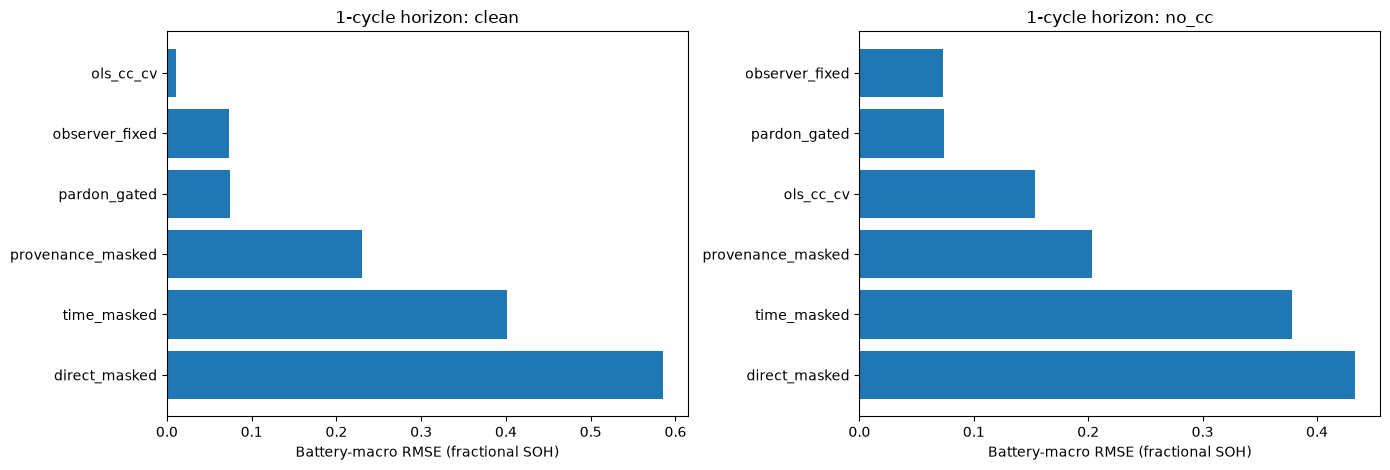

In [12]:
fig,axes=plt.subplots(1,2,figsize=(14,4.8))
for ax,scenario in zip(axes,['clean','no_cc']):
    d=summary[(summary.horizon==1)&(summary.scenario==scenario)].sort_values('mean_cell_rmse')
    ax.barh(d.model,d.mean_cell_rmse)
    ax.invert_yaxis();ax.set_title(f'1-cycle horizon: {scenario}');ax.set_xlabel('Battery-macro RMSE (fractional SOH)')
plt.tight_layout()
plt.savefig(OUT/'rmse_clean_vs_no_cc.png',dpi=170)
plt.show()

## 9 · Model integrity / interpretation checks

The gate's value is a **learned numerical coefficient**, not an independently validated probability that a measurement is trustworthy. Its average can be inspected, but physical interpretation requires source-based labels or interventions. Never infer true rest or actual recovery from the missing-data flags.

Next experiments, only if the learned gate improves validation and multiple held-out cells:
- Remove the slow-trend prior; keep a same-parameter MLP/GRU observer.
- Replace the provenance signals with shuffled (within-training-cell) provenance as an information-value test.
- Evaluate channel-specific masking, calibrated uncertainty, and genuinely partial-charge samples from raw measurements.
- Add an independently documented external dataset. Repeatedly inspecting CX2_38 has made it unsuitable for a claim of pristine blind external testing.

In [13]:
# Inspect PARDON evidence gates and latent slow-trend summaries on saved held-out forecasts.
pred_file=OUT/'predictions'/f'{folds[0]["name"]}_pardon_gated.csv'
pred_df=pd.read_csv(pred_file)
print('Mean gate across evaluation scenarios:')
display(pred_df.groupby('scenario')[['gate_mean','slow_state_proxy']].agg(['mean','std']).round(4))

manifest={'research_title':'PARDON-SOH evidence-aware observer prototype',
          'run_mode':RUN_MODE,'task':'SOH forecast at exact cycle ordinal k+h, h=1,3,5',
          'training_filter':'3pp jump exclusion on training cells only; not validated noise cleaning',
          'missingness':'synthetic masked features, no claim of physical partial charging',
          'unknown_intervals':'recording gaps, not verified rest',
          'model_selection':'0.60 validation clean RMSE + 0.40 validation no_cc RMSE',
          'seeds':list(SEEDS),'folds':[dict(heldout=f['held'],validation=f['val_cell']) for f in folds],
          'features':FEATURES,'horizons':list(HORIZONS),
          'limitations':['not proven novel','latent slow state not physically identified',
                         'observed test cells previously explored','synthetic missingness != natural missingness']}
(OUT/'EXPERIMENT_MANIFEST.json').write_text(json.dumps(manifest,indent=2))
print('Saved summary, checkpoints, predictions, manifest in',OUT)

Mean gate across evaluation scenarios:


gate_mean         slow_state_proxy        
                   mean     std             mean     std
scenario                                                
clean            0.4794  0.0003           0.9869  0.0001
history_block    0.3194  0.0002           0.9869  0.0001
no_cc            0.4809  0.0002           0.9869  0.0001
no_cv            0.4802  0.0003           0.9869  0.0001
random30         0.4777  0.0082           0.9869  0.0001

Saved summary, checkpoints, predictions, manifest in C:\Projects\Battery_Soh\pre processed ready to use data\pardon_soh_results\smoke


### What would count as a useful outcome?

**Promising evidence:** PARDON improves no-CC/history-block forecasts on most outer held-out cells versus both the fixed-update observer and provenance-matched Transformer, without a large clean-data penalty. Its uncertainty intervals should also be empirically better calibrated.

**Negative evidence:** gains are isolated to one cell, disappear against the matched controls, or rely on implausible training-only assumptions. Then simplify or discard the new architecture rather than adding more modules.

**For publication:** reproduce published masked time-series and battery health state estimation baselines, verify measurement provenance from source data, and evaluate additional independent battery datasets. This notebook is an implementable research hypothesis, not proof of novelty or superiority.